# Практичне заняття № 4 — Наївний байєсівський класифікатор

**Завдання.** Створити спам-фільтр на основі наївного баєсівського класифікатора
на даних датасету з підбірки [Kaggle: spam](https://www.kaggle.com/datasets?search=spam).
**Дослідити проблему нульової імовірності для алгоритму Баєса.**

**Датасет: SMS Spam Collection** (UCI) — 5 572 SMS-повідомлення англійською, з
них 747 спаму (13.4 %) і 4 825 звичайних (`ham`).

## Теорія

За теоремою Баєса ймовірність того, що повідомлення належить класу $c$ за умови
спостереження слів $w_1, \dots, w_n$:

$$P(c \mid w_1 \dots w_n) = \frac{P(c) \cdot P(w_1 \dots w_n \mid c)}{P(w_1 \dots w_n)}$$

Класифікатор називається **наївним**, бо припускає умовну незалежність слів:

$$P(w_1 \dots w_n \mid c) \approx \prod_{i=1}^{n} P(w_i \mid c)$$

Для тексту це припущення явно хибне (слова корелюють), але на практиці метод
працює добре. Знаменник однаковий для всіх класів, тому для порівняння класів
достатньо чисельника.

## Проблема нульової ймовірності

Саме добуток і створює головну вразливість методу. Оцінка ймовірності слова —
частотна:

$$P(w_i \mid c) = \frac{\text{count}(w_i, c)}{\sum_w \text{count}(w, c)}$$

Якщо слово $w_i$ **жодного разу не зустрілось** у навчальних документах класу $c$,
то $P(w_i \mid c) = 0$, і **весь добуток обертається на нуль** незалежно від того,
наскільки решта слів свідчить на користь цього класу. Одне незнайоме слово
анулює всі інші свідчення.

Нижче ця проблема демонструється кількісно, а потім усувається згладжуванням.

In [1]:
# --- Підготовка даних -------------------------------------------------------
# Ноутбук має запускатися і локально, і в Colab. Якщо потрібного файлу немає,
# він завантажується з Kaggle. Форму таблиці перевіряємо одразу: Kaggle може
# оновити версію набору, і краще впасти тут, ніж мовчки отримати інші числа,
# ніж у звіті.
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path


def _in_colab():
    if "google.colab" in sys.modules:
        return True
    try:
        return importlib.util.find_spec("google.colab") is not None
    except (ImportError, ValueError):
        # find_spec імпортує батьківський пакет; без нього — це не Colab
        return False


IN_COLAB = _in_colab()
DATA = Path("data"); DATA.mkdir(exist_ok=True)
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)

# (локальна назва, slug на Kaggle, файл у наборі, колонок, рядків, кодування)
DATASETS = [
    ('spam-ham.csv', 'muhammadahmedansari/ham-spam-messages-dataset',
     'spam-ham v2.csv', 2, 5572, 'latin-1')
]


def _ensure_packages():
    """У Colab більшість пакетів уже є; доставляємо лише те, чого бракує."""
    missing = [p for p in ("pandas", "sklearn", "matplotlib", "seaborn", "kagglehub")
               if importlib.util.find_spec(p) is None]
    if missing:
        names = {"sklearn": "scikit-learn"}
        pkgs = [names.get(m, m) for m in missing]
        print("встановлюю:", ", ".join(pkgs))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)


def _check(path, ncols, nrows, encoding):
    # Перевіряємо і колонки, і рядки: нова версія набору може зберегти структуру,
    # але змінити обсяг — і числа у звіті тихо перестануть збігатися.
    import pandas as pd
    got = pd.read_csv(path, encoding=encoding).shape
    if got != (nrows, ncols):
        raise ValueError(f"{path.name}: очікували {nrows}×{ncols}, отримали {got[0]}×{got[1]}")


def _ensure(local, slug, member, ncols, nrows, encoding):
    dst = DATA / local
    if dst.exists():
        _check(dst, ncols, nrows, encoding)
        print(f"на місці: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    if importlib.util.find_spec("kagglehub"):
        import kagglehub
        print(f"завантажую {slug} …")
        root = Path(kagglehub.dataset_download(slug))
        src = next(iter(root.rglob(member)), None)
        if src is None:   # назву файлу в наборі могли змінити — беремо найбільший CSV
            src = max(root.rglob("*.csv"), key=lambda f: f.stat().st_size)
        shutil.copy(src, dst)
        _check(dst, ncols, nrows, encoding)
        print(f"готово: {dst} ({dst.stat().st_size / 1e6:.1f} МБ)")
        return
    raise FileNotFoundError(
        f"{dst} не знайдено. Візьміть набір за адресою "
        f"https://www.kaggle.com/datasets/{slug} і покладіть файл у {DATA}/ "
        f"під назвою {local}."
    )


if IN_COLAB:
    _ensure_packages()
for _args in DATASETS:
    _ensure(*_args)

на місці: data/spam-ham.csv (0.5 МБ)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
ASSETS = Path("assets"); ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
np.random.seed(RANDOM_STATE)

## 1. Дані

In [3]:
df = pd.read_csv("data/spam-ham.csv", encoding="latin-1")
df = df.rename(columns={"v1": "label", "v2": "text"})[["label", "text"]]
df["text"] = df["text"].astype(str)

print(f"Повідомлень: {len(df)}")
print(f"Класи: {df['label'].value_counts().to_dict()}")
print(f"Частка спаму: {(df['label']=='spam').mean():.1%}")
print(f"Повних дублікатів: {df.duplicated().sum()}")
print(f"\nСередня довжина, символів: ham={df[df.label=='ham'].text.str.len().mean():.0f}, "
      f"spam={df[df.label=='spam'].text.str.len().mean():.0f}")
print("\nПриклад спаму:\n ", df[df.label=="spam"].text.iloc[0][:150])
print("\nПриклад ham:\n ", df[df.label=="ham"].text.iloc[0][:150])

Повідомлень: 5572
Класи: {'ham': 4825, 'spam': 747}
Частка спаму: 13.4%
Повних дублікатів: 401

Середня довжина, символів: ham=72, spam=139

Приклад спаму:
  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075ove

Приклад ham:
  Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


In [4]:
# Позитивна подія — спам. Хибнопозитивне спрацювання (блокування
# нормального повідомлення) для користувача гірше, ніж пропущений спам,
# тому далі особлива увага до precision.
y = (df["label"] == "spam").astype(int)
X_text = df["text"]

X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print(f"Навчальна: {len(X_train)} ({y_train.sum()} спаму)")
print(f"Тестова:   {len(X_test)} ({y_test.sum()} спаму)")

Навчальна: 4179 (560 спаму)
Тестова:   1393 (187 спаму)


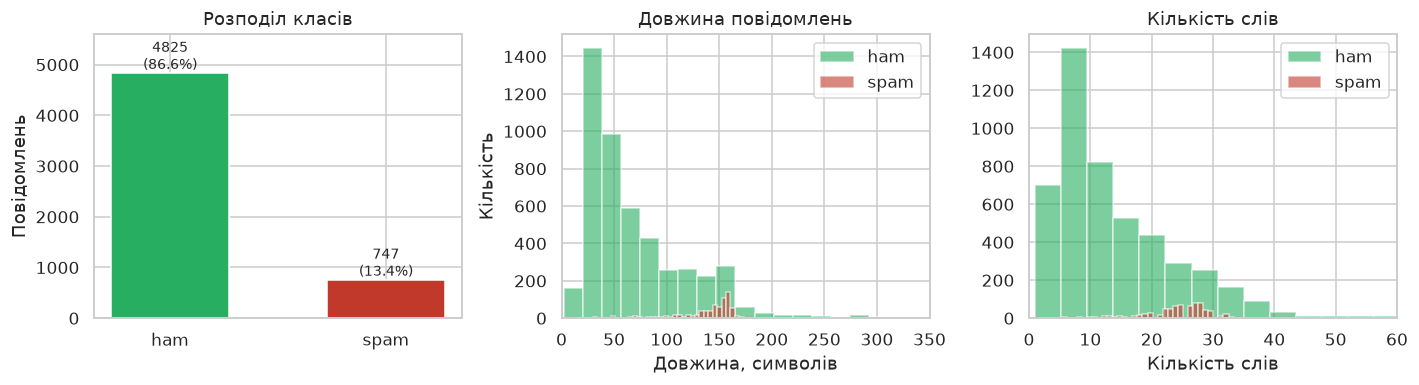

In [5]:
# --- Рисунок 1: огляд даних ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
vc = df["label"].value_counts()
axes[0].bar(["ham", "spam"], [vc["ham"], vc["spam"]], color=["#27ae60", "#c0392b"], width=0.55)
axes[0].set_title("Розподіл класів"); axes[0].set_ylabel("Повідомлень")
for i, v in enumerate([vc["ham"], vc["spam"]]):
    axes[0].text(i, v + 90, f"{v}\n({v/len(df):.1%})", ha="center", fontsize=9)
axes[0].set_ylim(0, 5600)

for lab, col in [("ham", "#27ae60"), ("spam", "#c0392b")]:
    axes[1].hist(df[df.label == lab].text.str.len(), bins=50, alpha=0.6, label=lab, color=col)
axes[1].set_xlabel("Довжина, символів"); axes[1].set_ylabel("Кількість")
axes[1].set_title("Довжина повідомлень"); axes[1].legend(); axes[1].set_xlim(0, 350)

for lab, col in [("ham", "#27ae60"), ("spam", "#c0392b")]:
    axes[2].hist(df[df.label == lab].text.str.split().str.len(), bins=40, alpha=0.6, label=lab, color=col)
axes[2].set_xlabel("Кількість слів"); axes[2].set_title("Кількість слів"); axes[2].legend()
axes[2].set_xlim(0, 60)
plt.tight_layout()
plt.savefig(ASSETS / "01-overview.png", bbox_inches="tight")
plt.show()

## 2. Векторизація тексту

`CountVectorizer` будує словник за навчальною вибіркою і перетворює кожне
повідомлення на вектор частот слів. **Словник будується лише за навчальними
даними** — саме тому в тестових повідомленнях неминуче з'являються невідомі слова,
і виникає проблема нульової ймовірності.

In [6]:
vec = CountVectorizer(lowercase=True)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
vocab = vec.get_feature_names_out()

print(f"Розмір словника: {len(vocab)}")
print(f"Матриця ознак: {Xtr.shape}, заповненість {Xtr.nnz / (Xtr.shape[0]*Xtr.shape[1]):.4%}")

Розмір словника: 7534
Матриця ознак: (4179, 7534), заповненість 0.1777%


## 3. Демонстрація проблеми нульової ймовірності

In [7]:
# Рахуємо частоти слів по класах на навчальній вибірці
counts_spam = np.asarray(Xtr[y_train.values == 1].sum(axis=0)).ravel()
counts_ham  = np.asarray(Xtr[y_train.values == 0].sum(axis=0)).ravel()

only_ham  = int(((counts_spam == 0) & (counts_ham > 0)).sum())
only_spam = int(((counts_ham == 0) & (counts_spam > 0)).sum())

print(f"Слів у словнику:                       {len(vocab)}")
print(f"Зустрічаються ТІЛЬКИ в ham:            {only_ham}  ({only_ham/len(vocab):.1%})")
print(f"Зустрічаються ТІЛЬКИ в spam:           {only_spam}  ({only_spam/len(vocab):.1%})")
print(f"Разом «однокласових» слів:             {only_ham+only_spam}  "
      f"({(only_ham+only_spam)/len(vocab):.1%} словника)")
print()
print(f"Тобто для {(only_ham+only_spam)/len(vocab):.0%} словника одна з умовних")
print("імовірностей дорівнює нулю ще до того, як ми побачили тестові дані.")

Слів у словнику:                       7534
Зустрічаються ТІЛЬКИ в ham:            5052  (67.1%)
Зустрічаються ТІЛЬКИ в spam:           1594  (21.2%)
Разом «однокласових» слів:             6646  (88.2% словника)

Тобто для 88% словника одна з умовних
імовірностей дорівнює нулю ще до того, як ми побачили тестові дані.


In [8]:
# Скільки ТЕСТОВИХ повідомлень містять хоча б одне слово з нульовою
# ймовірністю для кожного з класів?
Xte_bin = (Xte > 0)
zero_for_spam = np.asarray(Xte_bin[:, counts_spam == 0].sum(axis=1)).ravel() > 0
zero_for_ham  = np.asarray(Xte_bin[:, counts_ham == 0].sum(axis=1)).ravel() > 0
zero_for_both = zero_for_spam & zero_for_ham

print(f"Тестових повідомлень: {Xte.shape[0]}")
print(f"  містять слово, невідоме класу spam: {zero_for_spam.sum():4}  ({zero_for_spam.mean():.1%})")
print(f"  містять слово, невідоме класу ham:  {zero_for_ham.sum():4}  ({zero_for_ham.mean():.1%})")
print(f"  обидві ймовірності нульові:          {zero_for_both.sum():4}  ({zero_for_both.mean():.1%})")
print()
print("Для останньої групи класифікатор без згладжування отримує 0 × ... = 0 для")
print("ОБОХ класів — рішення невизначене й вироджується у вибір за замовчуванням.")

Тестових повідомлень: 1393
  містять слово, невідоме класу spam: 1153  (82.8%)
  містять слово, невідоме класу ham:   238  (17.1%)
  обидві ймовірності нульові:           106  (7.6%)

Для останньої групи класифікатор без згладжування отримує 0 × ... = 0 для
ОБОХ класів — рішення невизначене й вироджується у вибір за замовчуванням.


In [9]:
# Власна реалізація наївного Баєса з керованим згладжуванням —
# щоб побачити механізм, а не лише результат sklearn.
def nb_fit(Xtr, y_train, alpha):
    # Оцінюємо P(w|c) = (count(w,c) + alpha) / (sum_w count(w,c) + alpha*|V|)
    out = {}
    for cls in (0, 1):
        cnt = np.asarray(Xtr[y_train.values == cls].sum(axis=0)).ravel().astype(float)
        total = cnt.sum()
        V = len(cnt)
        out[cls] = (cnt + alpha) / (total + alpha * V)
    priors = {cls: (y_train.values == cls).mean() for cls in (0, 1)}
    return out, priors

def nb_predict_logprob(Xte, probs, priors):
    # Працюємо в логарифмах: добуток сотень імовірностей інакше
    # спричиняє машинне зникнення порядку (underflow)
    with np.errstate(divide="ignore"):
        logp = {cls: np.log(probs[cls]) for cls in (0, 1)}
    scores = {}
    for cls in (0, 1):
        scores[cls] = np.asarray(Xte @ logp[cls]).ravel() + np.log(priors[cls])
    return scores

# alpha = 0 — БЕЗ згладжування
probs0, priors0 = nb_fit(Xtr, y_train, alpha=0.0)
scores0 = nb_predict_logprob(Xte, probs0, priors0)

n_inf_spam = np.isneginf(scores0[1]).sum()
n_inf_ham  = np.isneginf(scores0[0]).sum()
n_inf_both = (np.isneginf(scores0[1]) & np.isneginf(scores0[0])).sum()

print("=== БЕЗ згладжування (alpha = 0) ===")
print(f"  log P(spam|d) = -inf у {n_inf_spam} повідомлень")
print(f"  log P(ham|d)  = -inf у {n_inf_ham} повідомлень")
print(f"  ОБИДВІ -inf (рішення неможливе):  {n_inf_both} з {Xte.shape[0]} ({n_inf_both/Xte.shape[0]:.1%})")
pred0 = (scores0[1] > scores0[0]).astype(int)
print(f"\n  Точність за таких умов: {accuracy_score(y_test, pred0):.4f}")
print(f"  F1 щодо спаму:          {f1_score(y_test, pred0):.4f}")

=== БЕЗ згладжування (alpha = 0) ===
  log P(spam|d) = -inf у 1153 повідомлень
  log P(ham|d)  = -inf у 238 повідомлень
  ОБИДВІ -inf (рішення неможливе):  106 з 1393 (7.6%)

  Точність за таких умов: 0.9562
  F1 щодо спаму:          0.8146


### Згладжування Лапласа

Проблема усувається додаванням псевдовідліку $\alpha$ до кожного слова:

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\sum_w \text{count}(w, c) + \alpha \cdot |V|}$$

За $\alpha = 1$ це класичне **згладжування Лапласа**, за $0 < \alpha < 1$ —
згладжування Лідстоуна. Жодна ймовірність більше не дорівнює нулю, і одне
незнайоме слово вже не анулює всі інші свідчення.

In [10]:
alphas = [0.0, 1e-10, 1e-5, 0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]
rows = []
for a in alphas:
    probs, priors = nb_fit(Xtr, y_train, alpha=a)
    sc = nb_predict_logprob(Xte, probs, priors)
    pred = (sc[1] > sc[0]).astype(int)
    undecidable = int((np.isneginf(sc[1]) & np.isneginf(sc[0])).sum())
    rows.append({
        "alpha": a,
        "Невизначених": undecidable,
        "Точність": accuracy_score(y_test, pred),
        "Precision (спам)": precision_score(y_test, pred, zero_division=0),
        "Recall (спам)": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

alpha_df = pd.DataFrame(rows)
alpha_df.to_csv("data/alpha-sweep.csv", index=False)
alpha_df.round(4)

,alpha,Невизначених,Точність,Precision (спам),Recall (спам),F1
0,0.000,106,0.9562,0.9437,0.7166,0.8146
1,0.000,0,0.9799,0.9543,0.8930,0.9227
2,0.000,0,0.9813,0.9548,0.9037,0.9286
3,0.001,0,0.9828,0.9553,0.9144,0.9344
4,0.010,0,0.9842,0.9609,0.9198,0.9399
5,0.100,0,0.9864,0.9667,0.9305,0.9482
6,0.500,0,0.9864,0.9719,0.9251,0.9479
7,1.000,0,0.9856,0.9771,0.9144,0.9448
8,2.000,0,0.9813,0.9820,0.8770,0.9266
9,5.000,0,0.9698,1.0000,0.7754,0.8735


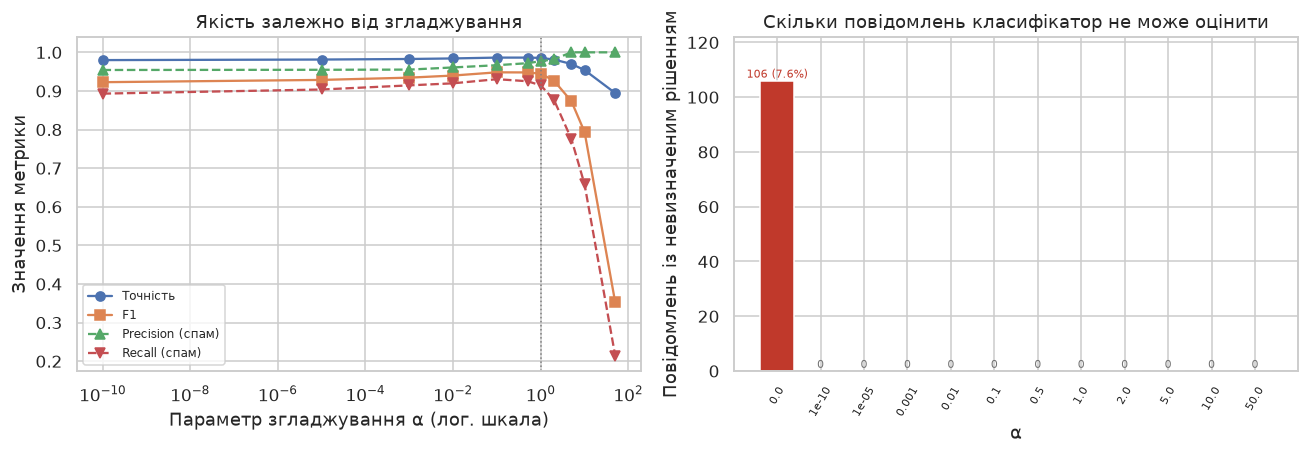

Найкращий F1 = 0.9482 при alpha = 0.1
Без згладжування (alpha=0): F1 = 0.8146, невизначених 106


In [11]:
# --- Рисунок 2: вплив згладжування ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_df = alpha_df[alpha_df["alpha"] > 0]

for col, style in [("Точність", "o-"), ("F1", "s-"),
                   ("Precision (спам)", "^--"), ("Recall (спам)", "v--")]:
    axes[0].plot(plot_df["alpha"], plot_df[col], style, label=col)
axes[0].set_xscale("log"); axes[0].set_xlabel("Параметр згладжування α (лог. шкала)")
axes[0].set_ylabel("Значення метрики")
axes[0].set_title("Якість залежно від згладжування")
axes[0].legend(fontsize=8); axes[0].axvline(1.0, color="gray", linestyle=":", linewidth=1)

bars = axes[1].bar(range(len(alpha_df)), alpha_df["Невизначених"], color="#c0392b")
axes[1].set_xticks(range(len(alpha_df)))
axes[1].set_xticklabels([str(a) for a in alpha_df["alpha"]], rotation=60, fontsize=7)
axes[1].set_xlabel("α"); axes[1].set_ylabel("Повідомлень із невизначеним рішенням")
axes[1].set_title("Скільки повідомлень класифікатор не може оцінити")
# Ненульовий стовпчик тут лише один: за будь-якого α > 0 невизначених рівно
# нуль. Підписуємо кожен стовпчик, щоб порожні місця читалися як справжні нулі,
# а не як відсутні дані.
for rect, v in zip(bars, alpha_df["Невизначених"]):
    axes[1].annotate(f"{int(v)} ({v / len(y_test):.1%})" if v else "0",
                     (rect.get_x() + rect.get_width() / 2, v),
                     textcoords="offset points", xytext=(0, 2), ha="center",
                     fontsize=7, color="#c0392b" if v else "0.45")
axes[1].margins(y=0.15)
plt.tight_layout()
plt.savefig(ASSETS / "02-smoothing.png", bbox_inches="tight")
plt.show()

best_row = alpha_df.loc[alpha_df["F1"].idxmax()]
print(f"Найкращий F1 = {best_row['F1']:.4f} при alpha = {best_row['alpha']}")
print(f"Без згладжування (alpha=0): F1 = {alpha_df.iloc[0]['F1']:.4f}, "
      f"невизначених {int(alpha_df.iloc[0]['Невизначених'])}")

## 4. Конкретний приклад анулювання

Візьмемо повідомлення, для якого без згладжування обидві ймовірності нульові, і
подивимось, які саме слова це спричинили.

In [12]:
idx = int(np.where(zero_for_both)[0][0])
msg = X_test.iloc[idx]
print("Повідомлення:")
print(" ", msg[:250])
print()
row = Xte_bin[idx].toarray().ravel()
words_in = np.where(row)[0]
killers_spam = [vocab[w] for w in words_in if counts_spam[w] == 0]
killers_ham  = [vocab[w] for w in words_in if counts_ham[w] == 0]
print(f"Слова, невідомі класу spam ({len(killers_spam)}): {killers_spam[:10]}")
print(f"Слова, невідомі класу ham  ({len(killers_ham)}): {killers_ham[:10]}")
print()
print("Кожне з цих слів дає множник 0, тож без згладжування обидва добутки")
print("перетворюються на нуль, і рішення ухвалити неможливо.")

Повідомлення:
  Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603

Слова, невідомі класу spam (1): ['lonely']
Слова, невідомі класу ham  (3): ['150p', 'jordan', 'visionsms']

Кожне з цих слів дає множник 0, тож без згладжування обидва добутки
перетворюються на нуль, і рішення ухвалити неможливо.


## 5. Різновиди наївного Баєса та способи векторизації

In [13]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
variants = []
for vec_name, vectorizer in [("CountVectorizer", CountVectorizer()),
                             ("TfidfVectorizer", TfidfVectorizer())]:
    for nb_name, model in [("MultinomialNB", MultinomialNB()),
                           ("BernoulliNB", BernoulliNB()),
                           ("ComplementNB", ComplementNB())]:
        pipe = make_pipeline(vectorizer.__class__(), model.__class__())
        s = cross_val_score(pipe, X_text, y, cv=cv, scoring="f1")
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        variants.append({
            "Векторизація": vec_name, "Модель": nb_name,
            "F1 (CV)": s.mean(),
            "Precision (спам)": precision_score(y_test, pred, zero_division=0),
            "Recall (спам)": recall_score(y_test, pred, zero_division=0),
        })

variants_df = pd.DataFrame(variants)
variants_df.pivot(index="Модель", columns="Векторизація", values="F1 (CV)").round(4)

Векторизація,CountVectorizer,TfidfVectorizer
Модель,,
BernoulliNB,0.9113,0.9113
ComplementNB,0.9268,0.9158
MultinomialNB,0.9491,0.8206


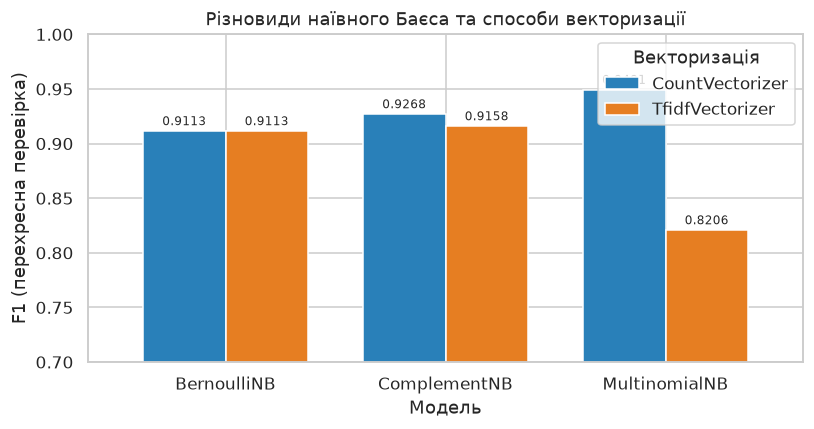

In [14]:
# --- Рисунок 3: різновиди NB ---
fig, ax = plt.subplots(figsize=(7.5, 4))
piv = variants_df.pivot(index="Модель", columns="Векторизація", values="F1 (CV)")
piv.plot.bar(ax=ax, color=["#2980b9", "#e67e22"], width=0.75, rot=0)
ax.set_ylabel("F1 (перехресна перевірка)")
ax.set_title("Різновиди наївного Баєса та способи векторизації")
ax.set_ylim(0.7, 1.0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.4f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig(ASSETS / "03-variants.png", bbox_inches="tight")
plt.show()

## 6. Які слова найбільше свідчать про спам

In [15]:
nb = MultinomialNB(alpha=1.0).fit(Xtr, y_train)
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
freq = counts_spam + counts_ham
mask = freq >= 15          # лише достатньо частотні слова

order = np.argsort(log_ratio[mask])
sel = np.where(mask)[0]
top_spam = [(vocab[sel[i]], log_ratio[sel[i]]) for i in order[-12:]][::-1]
top_ham  = [(vocab[sel[i]], log_ratio[sel[i]]) for i in order[:12]]

print("Найсильніші індикатори СПАМУ:")
for w, v in top_spam: print(f"  {w:12} log-ratio = {v:+.2f}")
print("\nНайсильніші індикатори HAM:")
for w, v in top_ham: print(f"  {w:12} log-ratio = {v:+.2f}")

Найсильніші індикатори СПАМУ:
  claim        log-ratio = +5.43
  prize        log-ratio = +5.14
  150p         log-ratio = +4.93
  tone         log-ratio = +4.72
  guaranteed   log-ratio = +4.59
  18           log-ratio = +4.59
  500          log-ratio = +4.59
  cs           log-ratio = +4.59
  1000         log-ratio = +4.41
  awarded      log-ratio = +4.31
  uk           log-ratio = +4.29
  150ppm       log-ratio = +4.24

Найсильніші індикатори HAM:
  gt           log-ratio = -4.55
  lt           log-ratio = -4.53
  he           log-ratio = -4.09
  lor          log-ratio = -3.83
  she          log-ratio = -3.81
  da           log-ratio = -3.80
  later        log-ratio = -3.72
  ì_           log-ratio = -3.42
  ll           log-ratio = -3.31
  doing        log-ratio = -3.26
  really       log-ratio = -3.24
  ask          log-ratio = -3.21


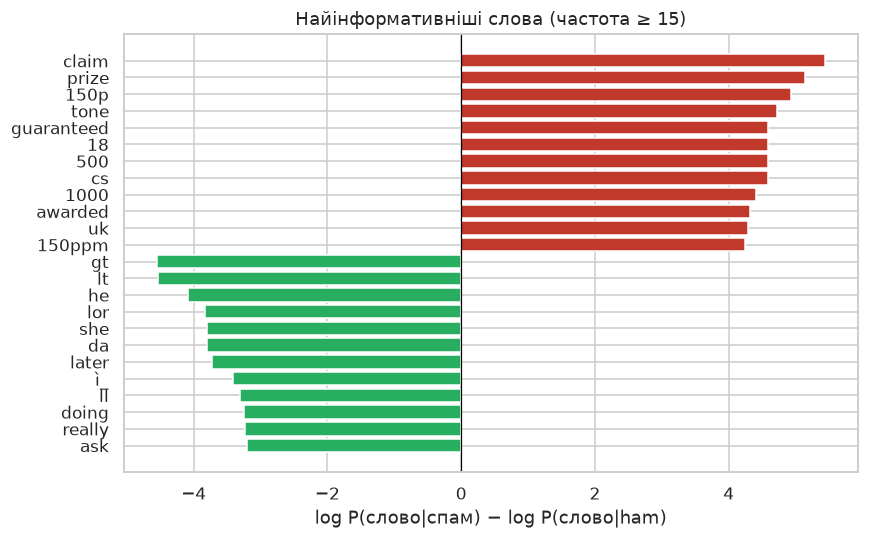

In [16]:
# --- Рисунок 4: індикативні слова ---
fig, ax = plt.subplots(figsize=(8, 5))
words = [w for w, _ in top_ham[::-1]] + [w for w, _ in top_spam[::-1]]
vals  = [v for _, v in top_ham[::-1]] + [v for _, v in top_spam[::-1]]
colors = ["#27ae60"] * len(top_ham) + ["#c0392b"] * len(top_spam)
ax.barh(words, vals, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("log P(слово|спам) − log P(слово|ham)")
ax.set_title("Найінформативніші слова (частота ≥ 15)")
plt.tight_layout()
plt.savefig(ASSETS / "04-words.png", bbox_inches="tight")
plt.show()

## 7. Підсумкова модель і порівняння з іншими методами

MultinomialNB(alpha=0.1) + CountVectorizer
              precision    recall  f1-score   support

         ham     0.9893    0.9950    0.9921      1206
        spam     0.9667    0.9305    0.9482       187

    accuracy                         0.9864      1393
   macro avg     0.9780    0.9628    0.9702      1393
weighted avg     0.9862    0.9864    0.9863      1393



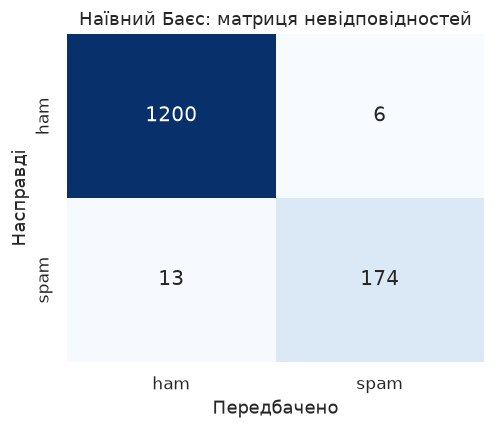

Хибнопозитивні (ham → spam): 6  ← втрачене нормальне повідомлення
Хибнонегативні (spam → ham): 13  ← спам у скриньці


In [17]:
best_alpha = float(best_row["alpha"])
final_nb = make_pipeline(CountVectorizer(), MultinomialNB(alpha=best_alpha))
final_nb.fit(X_train, y_train)
pred = final_nb.predict(X_test)

print(f"MultinomialNB(alpha={best_alpha}) + CountVectorizer")
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=4))

fig, ax = plt.subplots(figsize=(4.6, 4))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"], annot_kws={"size": 13})
ax.set_xlabel("Передбачено"); ax.set_ylabel("Насправді")
ax.set_title("Наївний Баєс: матриця невідповідностей")
plt.tight_layout()
plt.savefig(ASSETS / "05-confusion.png", bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Хибнопозитивні (ham → spam): {fp}  ← втрачене нормальне повідомлення")
print(f"Хибнонегативні (spam → ham): {fn}  ← спам у скриньці")

In [18]:
final_rows = []
for name, model in [
    (f"Наївний Баєс (α={best_alpha})", make_pipeline(CountVectorizer(), MultinomialNB(alpha=best_alpha))),
    ("Логістична регресія", make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000))),
    ("Лінійний SVM", make_pipeline(TfidfVectorizer(), LinearSVC(random_state=RANDOM_STATE))),
    ("Випадковий ліс", make_pipeline(CountVectorizer(), RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))),
]:
    s = cross_val_score(model, X_text, y, cv=cv, scoring="f1")
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    final_rows.append({
        "Модель": name, "F1 (CV)": s.mean(),
        "Точність": accuracy_score(y_test, p),
        "Precision (спам)": precision_score(y_test, p, zero_division=0),
        "Recall (спам)": recall_score(y_test, p, zero_division=0),
    })

final = pd.DataFrame(final_rows).set_index("Модель")
final.to_csv("data/results-summary.csv")
final.round(4)

,F1 (CV),Точність,Precision (спам),Recall (спам)
Модель,,,,
Наївний Баєс (α=0.1),0.9544,0.9864,0.9667,0.9305
Логістична регресія,0.8833,0.9713,0.9933,0.7914
Лінійний SVM,0.9513,0.9864,0.9884,0.9091
Випадковий ліс,0.9118,0.9698,1.0000,0.7754


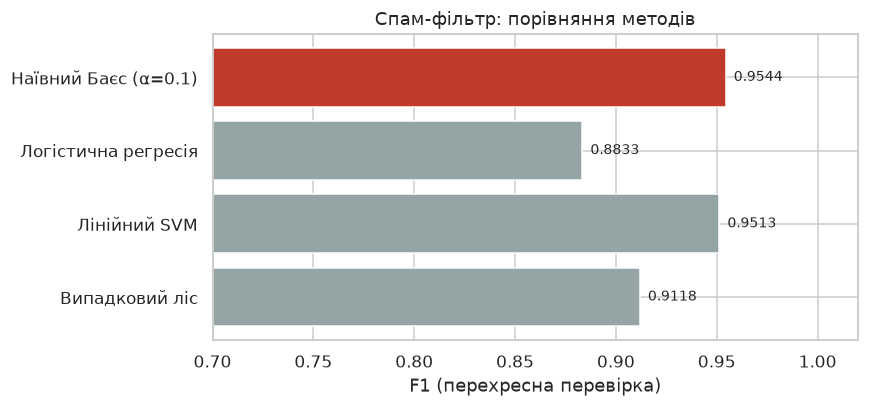

In [19]:
# --- Рисунок 5: порівняння методів ---
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#c0392b" if "Баєс" in i else "#95a5a6" for i in final.index]
bars = ax.barh(final.index[::-1], final["F1 (CV)"][::-1], color=colors[::-1])
ax.set_xlabel("F1 (перехресна перевірка)")
ax.set_title("Спам-фільтр: порівняння методів")
ax.set_xlim(0.7, 1.02)
for b, v in zip(bars, final["F1 (CV)"][::-1]):
    ax.text(v + 0.004, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(ASSETS / "06-final.png", bbox_inches="tight")
plt.show()

## 8. Підсумок

In [20]:
print("Вплив згладжування:"); print(alpha_df.round(4).to_markdown(index=False)); print()
print("Різновиди NB:");       print(variants_df.round(4).to_markdown(index=False)); print()
print("Порівняння методів:"); print(final.round(4).to_markdown())

Вплив згладжування:
|   alpha |   Невизначених |   Точність |   Precision (спам) |   Recall (спам) |     F1 |
|--------:|---------------:|-----------:|-------------------:|----------------:|-------:|
|   0     |            106 |     0.9562 |             0.9437 |          0.7166 | 0.8146 |
|   0     |              0 |     0.9799 |             0.9543 |          0.893  | 0.9227 |
|   0     |              0 |     0.9813 |             0.9548 |          0.9037 | 0.9286 |
|   0.001 |              0 |     0.9828 |             0.9553 |          0.9144 | 0.9344 |
|   0.01  |              0 |     0.9842 |             0.9609 |          0.9198 | 0.9399 |
|   0.1   |              0 |     0.9864 |             0.9667 |          0.9305 | 0.9482 |
|   0.5   |              0 |     0.9864 |             0.9719 |          0.9251 | 0.9479 |
|   1     |              0 |     0.9856 |             0.9771 |          0.9144 | 0.9448 |
|   2     |              0 |     0.9813 |             0.982  |          0.877  |